In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')
%cd /content/drive/MyDrive/Colab_AI 영상처리

Mounted at /content/drive
/content/drive/MyDrive/Colab_AI 영상처리


In [3]:
Image_Path = Path('picture/downtown.png')
assert Image_Path.exists(), '이미지가 없습니다.'

In [4]:
image = cv2.imread(str(Image_Path))
if image is None:
  raise FileNotFoundError('이미지가 없습니다')

# 1. Neon Edge 이미지 준비

In [5]:
# Canny() 사전작업 :: 가우시안 블러 + 흑백
blur = cv2.GaussianBlur(image, (5, 5), 0)
gray = cv2.cvtColor(
    blur,
    cv2.COLOR_BGR2GRAY    # imread() 결과물(BGR) -> 흑백
)

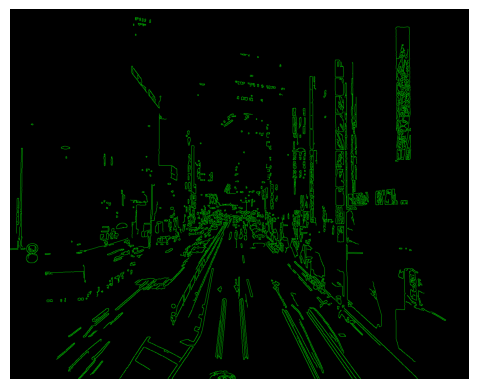

In [13]:
from matplotlib.colors import ListedColormap
# ListedColormap() 찾아보고, 초록색 경계선 표현

edges = cv2.Canny(gray, 20, 150)

plt.imshow(edges, cmap=ListedColormap(['black', 'lime']))
plt.axis('off')
plt.show()

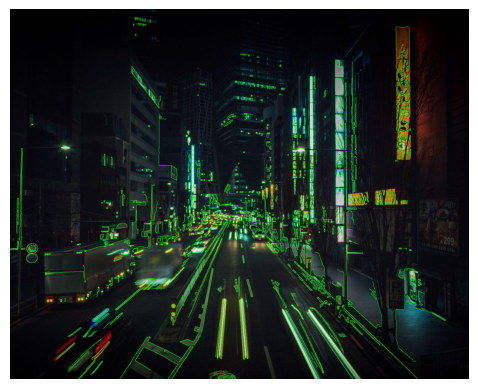

In [14]:
# Neon Overlay 표현 :: 원본 사진에 경계선 입히기
# 1. 원본 사진 준비
original = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

overlay = original.copy()

# 원본의 (0, 0)이랑 edges의 (0, 0)는 위치가 동일
#   => edges의 초록 경계선 위치를 참고하여, original에 하나씩 그리기
#     (ex) edges[100, 100] 초록 경계선 그어져있음 -> original[100][100] 그리면

overlay[edges == 255] = [0, 255, 0]

plt.imshow(overlay)
plt.axis('off')
plt.show()